---
title: "Luedeking-Piret: refitting alpha and beta from the one run whose raw data are printed"
description: "Luedeking and Piret (1959) relate lactic acid formation to growth and to biomass, dP/dt = alpha dN/dt + beta N, and print six (alpha, beta) pairs, one per pH. Only the pH 6.0 run has raw data in the paper, so this page refits that pair three ways, tests the two-term form against the two one-term laws the paper itself rejects, measures how well Table II checks itself, and puts the relation into a pymrm batch and plug-flow fermenter checked against its closed form. The refit is a consistency check on the authors' own graphical fit, not a validation of the model."
categories: [sec:J, struct:S1, tier:T0, data:tier2, phase:liquid]
date: 2026-08-14
---

# Luedeking-Piret: refitting $\alpha$ and $\beta$ from the one run whose raw data are printed

**Catalog ID:** `J4.4` · **Structures:** `S1` · **Tier:** T0

## Background

> **Luedeking, R.** and **Piret, E. L.**, *A Kinetic Study of the Lactic Acid
> Fermentation. Batch Process at Controlled pH*, **Journal of Biochemical and
> Microbiological Technology and Engineering 1**(4), 393-412 (1959),
> doi:`10.1002/jbmte.390010406`.

The paper is on disk and all twenty pages were read at the file's native
300 ppi (CCITT-G4 bilevel, per `pdfimages -list`). Identity is confirmed from
its first page: masthead, title, the by-line *"ROBERT LUEDEKING and EDGAR L.
PIRET / Department of Chemical Engineering, University of Minnesota"*, and the
Summary, which prints the relation this case is about.

**Every decimal point in this paper is a British mid-dot**, and the scan's text
layer relocates and drops them: it renders book p. 406's `pH 5.4` as `pH 3.4`,
and the U.O.D. definition `N = 0.125r` as `N = 0.12%`. No number on this page
came off the text layer; it was used only to search, and every numeral was read
on a crop of the 300 ppi image enlarged to digit scale. Book page = PDF page +
392, read off the printed running heads.

**The paper's symbols are $\alpha$ and $\beta$.** The catalogue entry writes the
relation with *a* and *b*; the Summary, eqs. (2) and (3), Table III, Fig. 10 and
the Nomenclature print Greek $\alpha$ and $\beta$, and this page keeps them.

### What the paper prints, and what it does not

Three tables: Table I (book p. 401, *"Bacterial density during batch
fermentation"*), Table II (book p. 402, *"Growth and lactic acid synthesis during
batch fermentation"*: $N$, $P$, $\mathrm{d}N/\mathrm{d}t$,
$\mathrm{d}P/\mathrm{d}t$, $k$ and $(1/N)(\mathrm{d}P/\mathrm{d}t)$) and Table III
(book p. 410, *"Experimental constants $\alpha$ and $\beta$ of equations 3 and 2
for each pH level"*). Tables I and II tabulate one fermentation only: book p. 401,
*"As an example, the rate information for the fermentation at pH 6·0 is tabulated
in Tables I and II"*.

**So five of Table III's six rows have no printed raw data anywhere in the paper,
and that half of the case is out of scope.** The check: `pdftotext -layout` over
all twenty pages and a case-sensitive `grep "Table"` finds the three captions,
the sentence just quoted and the cross-reference on book p. 409, and nothing
else; the case-insensitive search adds only the word *"unsuitable"* on book
p. 398. The only ruled blocks among the rendered pages are on PDF pages 9, 10 and
18. The other five fermentations appear as plotted curves in Figs. 4-11 and as
fitted constants in Table III. **No curve is digitised on this page.**

### What this page does

The Summary:

> *"It was found that the instantaneous rate of acid formation d$P$/d$t$, could
> be related to the instantaneous rate of bacterial growth d$N$/d$t$, and to the
> bacterial density $N$, throughout a fermentation at a given pH, by the
> expression* $\mathrm{d}P/\mathrm{d}t = \alpha\,\mathrm{d}N/\mathrm{d}t +
> \beta N$ *where the constants $\alpha$ and $\beta$ are determined by the pH of
> the fermentation."*

1. **Refit $\alpha$ and $\beta$ from Tables I and II** and compare with Table
   III's printed pH 6.0 pair, by three routes, one of which uses no
   differentiated column.
2. **Test the two-term form against the two one-term nulls**, both of them
   models the paper itself names and rejects.
3. **Report the pH trends of the six printed pairs** without refitting five of
   them, and say what six numbers can and cannot establish.
4. **Put the relation into pymrm** as a source term in a batch and in a
   plug-flow fermenter, checked against the closed form the model has.

**The refit is a consistency check on the authors' own fit, not a validation of
their model.** Book p. 410: *"The constants $\alpha$ and $\beta$ are determined
from the plots of Fig. 11"*, and Fig. 11 plots $(1/N)(\mathrm{d}P/\mathrm{d}t)$
against $k$, which are Table II's last two columns. The data on both sides of the
comparison are the same measurements.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.27.11"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "J4.4-luedeking-piret"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

## The published model

Book p. 408: *"A reasonably close correlation can be obtained if it be assumed
that the rate of acid synthesis is related **both** to the rate of growth and to
the quantity of bacteria present, using the simplest possible relationship"*:

$$\frac{\mathrm{d}P}{\mathrm{d}t} = \alpha\,\frac{\mathrm{d}N}{\mathrm{d}t}
   + \beta N \tag{2}$$

*"where $\alpha$ and $\beta$ are constants of proportionality"*. Then, *"since,
by definition, $k = (1/N)(\mathrm{d}N/\mathrm{d}t)$, the equation finally
simplifies to"*:

$$\frac{1}{N}\frac{\mathrm{d}P}{\mathrm{d}t} = \alpha k + \beta \tag{3}$$

**Eq. (3) is eq. (2) divided by $N$ and nothing else.** They are the same model
and not the same fit: least squares on eq. (3) weights each row equally, least
squares on eq. (2) weights it by $N^2$, and $N$ rises down Table II by the factor
printed below. The page reports both.

### The two nulls are the paper's own

Book p. 410:

> *"during the phase of logarithmic growth the two common assumptions mentioned
> above for relating rate of acid production to growth are both valid. This is
> true because $(\mathrm{d}N/\mathrm{d}t) = kN$, and during the logarithmic
> phase $k$ is a constant, $k_c$. Thus one can state with equal validity that
> during the logarithmic phase the rate of acid production is proportional to
> the growth rate of the bacteria, or that during this phase the rate of acid
> production is proportional to the quantity of bacteria present. **Neither
> statement was found to hold true outside of the period of logarithmic
> growth**, while equation 3, of course, was found to apply throughout the
> entire fermentation cycle."*

So the nulls are $\beta = 0$ (*"proportional to the growth rate"*) and
$\alpha = 0$ (*"proportional to the quantity of bacteria present"*).

### The crossover the paper describes in words

Book p. 410: *"In the early phases of a normal fermentation when the specific
growth rate is high, the first term of equation 3 is the important one, while
towards the end of the fermentation the second term becomes more important."*
The two terms of eq. (3) are equal at

$$k^{*} = \beta/\alpha \quad (\mathrm{h}^{-1}),$$

the specific growth rate below which the fermentation is no longer
growth-dominated. It is computed for all six pH levels, and the time at which
the pH 6.0 run crosses it is root-found on Table II by two routes that share no
column.

### Units

Table III's footnotes are the only place that gives units: *"$\alpha$ has the
units mg lactic/U.O.D."* and *"$\beta$ has the units mg lactic/U.O.D./h"*. The
Nomenclature on book p. 411 lists *"$\alpha$, $\beta$ Constants"* with none.
$N$ is not a cell count: book p. 400 defines U.O.D. optically and says *"one
unit of optical density corresponded to between 150,000,000 and 450,000,000
cells as determined by plate counts"*, so the constants inherit an optical
surrogate for biomass.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pymrm.checks import observed_orders

from gallery_utils import Claims, cite_data, load_data, load_meta
from model import (ClosedForm, PlugFlowFermenter, K_LOG, batch_march, digit_detection,
                   interpolant, ols, refit_all, rms)

plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5})
# Okabe-Ito, assigned in fixed order
C_BLUE, C_ORANGE, C_GREEN = "#0072B2", "#D55E00", "#009E73"
C_PURPLE, C_GREY = "#CC79A7", "0.45"
claims = Claims(PAGE.split("-")[0])
EPS = np.finfo(float).eps

T1 = load_data("luedeking1959-table1-bacterial-density.csv", page=PAGE)
T2 = load_data("luedeking1959-table2-growth-acid.csv", page=PAGE)
T3 = load_data("luedeking1959-table3-alpha-beta-vs-ph.csv", page=PAGE)
for _n in ("luedeking1959-table1-bacterial-density.csv",
           "luedeking1959-table2-growth-acid.csv",
           "luedeking1959-table3-alpha-beta-vs-ph.csv"):
    print(cite_data(load_meta(_n, page=PAGE)))
print(f"\nTable I  : {len(T1)} rows, {T1.time_h.min():.2f}-{T1.time_h.max():.2f} h")
print(f"Table II : {len(T2)} rows, {T2.time_h.min():.2f}-{T2.time_h.max():.2f} h,"
      f" {T2.notna().sum().sum()} filled cells of {T2.size}")
print(f"Table III: {len(T3)} rows, pH {T3.pH.min():.1f}-{T3.pH.max():.1f}")

# the printed pH 6.0 pair, looked up in the CSV, never retyped
_r60 = T3.loc[T3.pH == 6.0].iloc[0]
ALPHA_PRINTED = float(_r60.alpha_mg_lactic_per_UOD)
BETA_PRINTED = float(_r60.beta_mg_lactic_per_UOD_h)
print(f"\nTable III, pH 6.0:  alpha = {ALPHA_PRINTED} mg lactic/U.O.D.,"
      f"  beta = {BETA_PRINTED} mg lactic/U.O.D./h")
N_SPAN = float(T2.N_UOD_per_ml.max() / T2.N_UOD_per_ml.min())
print(f"N rises by a factor of {N_SPAN:.1f} down Table II")

Luedeking, R.; Piret, E. L. (1959) — "A Kinetic Study of the Lactic Acid Fermentation. Batch Process at Controlled pH", Journal of Biochemical and Microbiological Technology and Engineering 1(4) 393-412 (1959), Department of Chemical Engineering, University of Minnesota, Minneapolis 14, Minnesota
 — doi:10.1002/jbmte.390010406 — transcription
Luedeking, R.; Piret, E. L. (1959) — "A Kinetic Study of the Lactic Acid Fermentation. Batch Process at Controlled pH", Journal of Biochemical and Microbiological Technology and Engineering 1(4) 393-412 (1959), Department of Chemical Engineering, University of Minnesota, Minneapolis 14, Minnesota
 — doi:10.1002/jbmte.390010406 — transcription
Luedeking, R.; Piret, E. L. (1959) — "A Kinetic Study of the Lactic Acid Fermentation. Batch Process at Controlled pH", Journal of Biochemical and Microbiological Technology and Engineering 1(4) 393-412 (1959), Department of Chemical Engineering, University of Minnesota, Minneapolis 14, Minnesota
 — doi:10.10

## Parameters and assumptions

**Nothing on this page is a chosen parameter.** The inputs are three printed
tables; the outputs are least-squares fits to them and two solver
discretisations. The conditions are those of the Table I and II footnote:
*"At 45°C, pH controlled at 6·0, on a 5 per cent glucose medium fortified with
3 per cent yeast extract and added mineral salts, L. delbrueckii"*.

**Assumption 1: the fits are unweighted least squares.** The authors fitted by a
straight line drawn through Fig. 11, an unstated weighting. This page uses
ordinary least squares in eq. (3)'s variables, the variables they plotted, and
reports the eq. (2) fit (the same problem weighted by $N^2$) beside it.

**Assumption 2: between the printed rows, $k(t)$ and $N(t)$ are monotone cubic
(PCHIP) interpolants of the printed columns.** They are used only where an
interpolant is unavoidable: $\int N\,\mathrm{d}t$ of the integral form, the
crossover root, and the prescribed $k(t)$ of the two pymrm models. A linear
interpolant is a break row, and the crossover is also reported on it.

**Assumption 3: the one-significant-figure row at $t = 2{\cdot}50$ h is used at
face value.** Table II prints one figure in three of its cells, against two and
three everywhere else. A break row drops it.

**No growth law is assumed.** Luedeking and Piret propose none. Where a closed
system is needed, $k$ is prescribed from the paper's own printed $k$ column,
which keeps the product-formation model separate from a growth model (J4.1,
J4.2).

In [3]:
# Table II checks itself. Book p. 400: the specific rates "were determined by
# dividing the instantaneous rates by N", so k and (1/N)(dP/dt) are quotients of
# the other printed columns by definition: an arithmetic check on the transcription.
_k = T2.dropna(subset=["k_per_h", "N_UOD_per_ml", "dNdt_UOD_per_ml_h"])
K_IDENT = np.abs(_k.dNdt_UOD_per_ml_h / _k.N_UOD_per_ml / _k.k_per_h - 1.0).to_numpy()
K_IDENT_MAX = float(K_IDENT.max())
_q = T2.dropna(subset=["invN_dPdt_mg_per_UOD_h", "N_UOD_per_ml", "dPdt_mg_per_ml_h"])
Q_IDENT = np.abs(_q.dPdt_mg_per_ml_h / _q.N_UOD_per_ml / _q.invN_dPdt_mg_per_UOD_h
                 - 1.0).to_numpy()
print(f"k = (1/N)(dN/dt) over {len(_k)} rows: max {K_IDENT_MAX:.6f}"
      f" at t = {_k.time_h.to_numpy()[np.argmax(K_IDENT)]:.2f} h, mean {K_IDENT.mean():.6f}")
print(f"(1/N)(dP/dt) over {len(_q)} rows:     max {Q_IDENT.max():.6f}"
      f" at t = {_q.time_h.to_numpy()[np.argmax(Q_IDENT)]:.2f} h")
print("The columns are rounded after the division, so they agree only to a few per"
      " cent;\nthat band is the resolution of the check, and its reach is measured next.")

DIGIT_CAUGHT, DIGIT_TOTAL = digit_detection(_k, K_IDENT_MAX)
DIGIT_FRAC = DIGIT_CAUGHT / DIGIT_TOTAL
print(f"\nOf the {DIGIT_TOTAL} single-digit substitutions available in the (N, dN/dt, k)"
      f" triple,\n{DIGIT_CAUGHT} ({DIGIT_FRAC:.2%}) break the identity by more than the"
      f" {K_IDENT_MAX:.4f} the true table shows;\nthe other {DIGIT_TOTAL - DIGIT_CAUGHT}"
      " stay inside that rounding band.")

# Table I against Table II's N, which Table II footnotes as "Interpolated"
NT1 = interpolant(T1.time_h, T1.N_UOD_per_ml)
_n2 = T2.dropna(subset=["N_UOD_per_ml"])
_n2 = _n2[(_n2.time_h >= T1.time_h.min()) & (_n2.time_h <= T1.time_h.max())]
_rel = np.abs(NT1(_n2.time_h.to_numpy()) / _n2.N_UOD_per_ml.to_numpy() - 1.0)
_rl = np.abs(interpolant(T1.time_h, T1.N_UOD_per_ml, "linear")(_n2.time_h.to_numpy())
             / _n2.N_UOD_per_ml.to_numpy() - 1.0)
print(f"\nInterpolating Table I onto Table II's {len(_n2)} overlapping times reproduces"
      f" its N to {rms(_rel):.6f} rms\nand {_rel.max():.6f} at worst"
      f" (t = {_n2.time_h.to_numpy()[np.argmax(_rel)]:.2f} h); a linear interpolant gives"
      f" {_rl.max():.6f} at worst.\nTable II footnotes its N as \"Interpolated\"; the residual is"
      " the difference between the authors' interpolation and these.")

k = (1/N)(dN/dt) over 25 rows: max 0.027356 at t = 3.50 h, mean 0.008089
(1/N)(dP/dt) over 22 rows:     max 0.018410 at t = 12.00 h
The columns are rounded after the division, so they agree only to a few per cent;
that band is the resolution of the check, and its reach is measured next.

Of the 2019 single-digit substitutions available in the (N, dN/dt, k) triple,
1764 (87.37%) break the identity by more than the 0.0274 the true table shows;
the other 255 stay inside that rounding band.

Interpolating Table I onto Table II's 26 overlapping times reproduces its N to 0.012495 rms
and 0.033774 at worst (t = 5.00 h); a linear interpolant gives 0.033333 at worst.
Table II footnotes its N as "Interpolated"; the residual is the difference between the authors' interpolation and these.


## The data

Three CSVs, one per printed table, transcribed cell by cell from 300 ppi crops
enlarged to digit scale; the sidecars carry the crop procedure, the footnotes
verbatim and the defect notes. Blank cells of Table II are left blank. The row
counts are printed by the cell above.

**Table III's pH column is printed a second time.** Book p. 400, running text:
the six fermentations were *"each of which was continuously controlled at a
different pH level (6·0, 5·6, 5·4, 5·2, 4·8 and 4·5)"*. The cell under *The six
pH levels* checks the CSV against it. The $\alpha$ and $\beta$ columns have no
second printing, and Table III has no internal identity: three independent
columns, no derived quantity.

### The stray mark in the pH 5·6 $\beta$ cell: reported, not repaired

At 150 ppi that cell renders as `-0-49`. **The value is 0·49, settled
arithmetic first and pixels last.**

1. **The minus reading breaks a relation this page checks.** $\beta$ falls
   strictly as the pH falls over all six levels, a claim with its smallest step
   as margin (`beta_monotone_margin`); read the mark as a sign and that margin
   turns negative, which a break row shows. This is a pattern in six printed
   numbers, not a derived identity, and it is labelled as one; a sign error is
   the size of error it catches.
2. **The paper plots this column on a zero-based axis.** Fig. 10 (book p. 407)
   plots $\beta$ against pH with all six markers clearly above the zero line,
   the pH 5·6 marker close to the printed value. This reading separates
   $+0{\cdot}49$ from $-0{\cdot}49$ and nothing more; no number off Fig. 10
   enters a CSV, a fit or a claim. The calibration is in the Table III sidecar.
3. **The pixels.** The mark is one small connected component, the size of the
   genuine mid-dots in the same column and far smaller than the page's one true
   hyphen, and the zero after it is complete. The pixel census is in the Table
   III sidecar. What the mark is (broken type, an ink speck, dirt) cannot be
   settled from one copy and is not guessed at.

**The CSV carries 0·49 and the sidecar carries the mark.**

### Related pages, and what is borrowed

J4.1 (`pages/J4.1-monod/`) and J4.2 carry growth kinetics, and J4.1's
`data/printed-growth-laws.csv` is loaded below, for one purpose: to search it.
It holds growth laws $\mu(S)$ and prose claims transcribed from three textbooks,
flagged and not repaired by J4.1 (its README). This page uses none of its rows:
the search for `luedeking`, `piret`, `lactic`, `product`, `alpha` and `beta` over
every cell is printed below, and its hit count is a claim. Luedeking and Piret
propose no growth law, and eq. (2) contains no substrate concentration, so there
is no number in that file this page could restate and none to reconcile.

- **J4.1 and J4.2 model growth; this page models product formation given
  growth.** Eq. (2) composes with either of their $\mu(S)$ laws.
- **Identifiability.** J4.1's problem was distinguishing rival nonlinear laws on
  one dataset. Eq. (3) is linear in both constants, so the fit has a unique
  optimum; its conditioning is the finding of Results section 2.

In [4]:
# The cross-page search: J4.1's CSV is loaded only to show it holds nothing to borrow.
J41 = load_data("printed-growth-laws.csv", page="J4.1-monod")
J41_TERMS = ("luedeking", "piret", "lactic", "product", "alpha", "beta")


def j41_hits(terms=J41_TERMS):
    """Cells of J4.1's printed-growth-laws.csv containing each term (case-insensitive)."""
    hay = J41.astype(str).apply(lambda s: s.str.lower())
    return {t: int(hay.apply(lambda c: c.str.contains(t, regex=False)).sum().sum())
            for t in terms}


J41_HITS = j41_hits()
print(f"pages/J4.1-monod/data/printed-growth-laws.csv: {len(J41)} rows, columns"
      f" {list(J41.columns)}")
for _t, _n in J41_HITS.items():
    print(f"    {_t:12s} {_n} hit(s)")
J41_TOTAL_HITS = sum(J41_HITS.values())
print(f"  {J41_TOTAL_HITS} hits in total: the file is about mu(S), this page about dP/dt"
      " given dN/dt and N.")

pages/J4.1-monod/data/printed-growth-laws.csv: 30 rows, columns ['key', 'source', 'page', 'equation_number', 'as_printed', 'flag']
    luedeking    0 hit(s)
    piret        0 hit(s)
    lactic       0 hit(s)
    product      0 hit(s)
    alpha        0 hit(s)
    beta         0 hit(s)
  0 hits in total: the file is about mu(S), this page about dP/dt given dN/dt and N.


## PyMRM implementation

Eq. (2) is a **source term**: it says how fast $P$ appears given $N$ and
$\mathrm{d}N/\mathrm{d}t$. The pymrm content is that source carried by two
reactor models, both closed by the paper's printed $k$ column (`model.py`):

$$\frac{\mathrm{d}N}{\mathrm{d}t} = k(t)\,N, \qquad
  \frac{\mathrm{d}P}{\mathrm{d}t} = \alpha\,k(t)\,N + \beta N .$$

**1. Batch fermenter** (`batch_march`). State $(N, P)$ marched by backward Euler,
each step solved by `newton` with `NumJac((1, 2))`: a one-cell shape whose last
axis is the field index, so the default stencil couples the two fields in full.
The step is linear in $(N, P)$, so newton's first iterate solves it and the next
confirms it; every call checks `success` and raises otherwise.

**2. Plug-flow fermenter** (`PlugFlowFermenter`). The same source in a steady
tube, $v\,\mathrm{d}c/\mathrm{d}z = s(c)$ with residence time $t = t_0 + z/v$.
Operators `construct_convflux_upwind` and `construct_div` (`nu=0`, Cartesian),
assembled once; `newton` with `NumJac((n, 2))`; outlet read with
`compute_boundary_values`. The boundary conditions use the outward normal,
$a\,\partial c/\partial n + b\,c = d$: at the inlet a Dirichlet feed
$\{a=0, b=1, d=(N_0, 0)\}$; at the outlet `{"outflow": True}`, the
first-order convection-only outlet whose face carries the last cell's value.

This is the paper's stated motivation (Summary): *"Kinetic data are needed ... to
permit rational design of continuous fermentation processes."* It is not
something Luedeking and Piret did, and no measurement in the paper tests it.

**The closed form.** With $k(t)$ prescribed, both models integrate exactly:

$$N(t) = N_0\exp\!\int_{t_0}^{t}\! k\,\mathrm{d}t', \qquad
  P(t) = P_0 + \alpha\,[N(t) - N_0] + \beta\!\int_{t_0}^{t}\! N\,\mathrm{d}t' ,$$

with $\int k$ exact on the PCHIP interpolant and $\int N$ by adaptive quadrature
broken at the printed times. The second formula is also the third fitting route
below: fit $P$ itself and no differentiated column enters.

In [5]:
_kk = T2.dropna(subset=["k_per_h"])
T_LO, T_HI = float(_kk.time_h.min()), float(_kk.time_h.max())
N_LO = float(T2.loc[T2.time_h == T_LO, "N_UOD_per_ml"].iloc[0])
CF = ClosedForm(_kk.time_h, _kk.k_per_h, N_LO)
N_REF = float(CF.N(T_HI))
P_REF = CF.P(T_HI, ALPHA_PRINTED, BETA_PRINTED)
_iN, _iN_err = CF.int_N(T_HI)
print(f"prescribed k(t): PCHIP through the {len(_kk)} printed k cells, {T_LO:.2f}-{T_HI:.2f} h")
print(f"closed form at t = {T_HI} h with the printed pair: N = {N_REF:.8f} U.O.D./ml,"
      f" P = {P_REF:.8f} mg/ml")
print(f"  quadrature of int N dt: {_iN:.12f}, error estimate {_iN_err:.1e} absolute")

prescribed k(t): PCHIP through the 25 printed k cells, 1.00-13.50 h
closed form at t = 13.5 h with the printed pair: N = 9.68777169 U.O.D./ml, P = 45.32220609 mg/ml
  quadrature of int N dt: 44.132924309039, error estimate 4.9e-13 absolute


## Results

### 1. The refit, three ways

Route A is eq. (3), the authors' own plotting variables. Route B is eq. (2), the
same model weighted by $N^2$. Route C integrates eq. (2) and fits the measured
$P$ column, with no differentiated column at all. All three are **fits** to the
fermentation the authors fitted; none is a test on new data.

In [6]:
PH_TEXT_P400 = (6.0, 5.6, 5.4, 5.2, 4.8, 4.5)   # book p. 400, running text (a source read)
R = refit_all(T1, T2, T3, ph_text=PH_TEXT_P400)
print(f"{'route':46s} {'alpha':>10s} {'beta':>10s}   rms")
print(f"{'A  eq.(3) OLS, the authors own axes (Fig. 11)':46s} {R['alpha_refit_eq3']:10.6f}"
      f" {R['beta_refit_eq3']:10.6f}   {R['eq3_refit_rms']:.6f} mg/U.O.D. h"
      f" ({R['n_rows_eq3']} rows)")
print(f"{'B  eq.(2) OLS, i.e. eq.(3) weighted by N^2':46s} {R['alpha_refit_eq2']:10.6f}"
      f" {R['beta_refit_eq2']:10.6f}   {R['eq2_refit_rms']:.6f} mg/ml h")
print(f"{'C  integral form, no differentiated column':46s} {R['alpha_refit_integral']:10.6f}"
      f" {R['beta_refit_integral']:10.6f}   {R['integral_refit_rms']:.6f} mg/ml")
print(f"{'   printed, Table III pH 6.0':46s} {ALPHA_PRINTED:10.6f} {BETA_PRINTED:10.6f}")
print(f"\nroute A against the printed pair: alpha {R['alpha_refit_eq3_vs_printed']:+.4%},"
      f" beta {R['beta_refit_eq3_vs_printed']:+.4%}")
print(f"spread over the three routes: alpha {R['alpha_route_spread']:.4%},"
      f" beta {R['beta_route_spread']:.4%}")
print(f"\nroute A standard errors: alpha {R['alpha_refit_eq3']:.6f} +- {R['alpha_se_eq3']:.6f},"
      f" beta {R['beta_refit_eq3']:.6f} +- {R['beta_se_eq3']:.6f}, R^2 {R['eq3_R2']:.6f}")
print(f"  the printed alpha is {R['printed_alpha_in_se']:.4f} standard errors from the fit,"
      f" the printed beta {R['printed_beta_in_se']:.4f}")
print(f"  corr(alpha, beta) = {R['alpha_beta_corr_eq3']:.6f}: the constants trade off")

route                                               alpha       beta   rms
A  eq.(3) OLS, the authors own axes (Fig. 11)    2.266562   0.528684   0.100792 mg/U.O.D. h (22 rows)
B  eq.(2) OLS, i.e. eq.(3) weighted by N^2       2.289913   0.510117   0.323004 mg/ml h
C  integral form, no differentiated column       2.272660   0.510150   0.153769 mg/ml
   printed, Table III pH 6.0                     2.200000   0.550000

route A against the printed pair: alpha +3.0256%, beta -3.8757%
spread over the three routes: alpha 1.0302%, beta 3.6396%

route A standard errors: alpha 2.266562 +- 0.130928, beta 0.528684 +- 0.049837, R^2 0.937439
  the printed alpha is 0.5084 standard errors from the fit, the printed beta 0.4277
  corr(alpha, beta) = -0.891902: the constants trade off


### 2. The printed pair sits on the ridge

$\alpha$ and $\beta$ are strongly anticorrelated in this fit, so quoting the two
relative errors separately overstates the disagreement: they largely cancel. The
measures that do not are (i) one constant refitted with the other *held at the
authors' value*, and (ii) what their pair costs in residual against the
least-squares optimum.

In [7]:
print(f"beta refitted with alpha held at the printed {ALPHA_PRINTED}:"
      f" {R['beta_given_printed_alpha']:.6f}"
      f" ({R['beta_given_printed_alpha'] / BETA_PRINTED - 1:+.4%} from the printed {BETA_PRINTED})")
print(f"alpha refitted with beta held at the printed {BETA_PRINTED}:"
      f" {R['alpha_given_printed_beta']:.6f}"
      f" ({R['alpha_given_printed_beta'] / ALPHA_PRINTED - 1:+.4%} from the printed {ALPHA_PRINTED})")
print(f"\nrms of eq.(3) residuals: least squares {R['eq3_refit_rms']:.6f}, the printed pair"
      f" {R['eq3_printed_pair_rms']:.6f}\n  the authors' straight-edge fit costs"
      f" {R['eq3_printed_pair_rms_penalty']:.4%} in rms against the optimum on the same"
      f" {R['n_rows_eq3']} points.")
print("A consistency result about their fitting, not about their model.")

beta refitted with alpha held at the printed 2.2: 0.551282 (+0.2331% from the printed 0.55)
alpha refitted with beta held at the printed 0.55: 2.216616 (+0.7553% from the printed 2.2)

rms of eq.(3) residuals: least squares 0.100792, the printed pair 0.101450
  the authors' straight-edge fit costs 0.6521% in rms against the optimum on the same 22 points.
A consistency result about their fitting, not about their model.


### 3. The two nulls, in both of the windows the paper distinguishes

Each null is fitted with its own best constant. **The direction of every ratio
below is algebra**: each null is an exactly nested submodel of the two-term fit
on the same rows in the same variables, so `rms_null / rms_two-term` cannot fall
below 1. Only the magnitude is a finding, and a ratio near 1 would say the
second term earns nothing.

That is what the paper says happens in the logarithmic phase, so the ratios are
computed over all rows, over the logarithmic plateau, and over the rows outside
it. The split is at $k = 0{\cdot}45$, which is not tuned: the printed $k$ column
has a gap there, and every row above it lies on a narrow plateau whose spread is
printed below. That plateau is the paper's $k_c$.

In [8]:
_f2 = T2.dropna(subset=["N_UOD_per_ml", "dNdt_UOD_per_ml_h", "dPdt_mg_per_ml_h"])
_x2 = np.column_stack([_f2.dNdt_UOD_per_ml_h.to_numpy(), _f2.N_UOD_per_ml.to_numpy()])
_dp = _f2.dPdt_mg_per_ml_h.to_numpy()
_sst = ((_dp - _dp.mean()) ** 2).sum()
_r2 = lambda pred: float(1 - ((_dp - pred) ** 2).sum() / _sst)
print(f"{'model (rate form, eq. (2) variables, mg/ml h)':48s} {'rms':>10s} {'x two-term':>11s}  R^2")
print(f"{'  dP/dt = alpha dN/dt + beta N  (two-term)':48s} {R['eq2_refit_rms']:10.6f}"
      f" {1.0:11.4f}  {_r2(_x2 @ ols(_x2, _dp)):.6f}")
print(f"{'  dP/dt = alpha dN/dt           (beta = 0)':48s} {R['eq2_null_growth_only_rms']:10.6f}"
      f" {R['eq2_null_growth_only_ratio']:11.4f}  {_r2(_x2[:, [0]] @ ols(_x2[:, [0]], _dp)):.6f}")
print(f"{'  dP/dt = beta N                (alpha = 0)':48s} {R['eq2_null_density_only_rms']:10.6f}"
      f" {R['eq2_null_density_only_ratio']:11.4f}  {_r2(_x2[:, [1]] @ ols(_x2[:, [1]], _dp)):.6f}")
print(f"integral form, P itself: growth-only x{R['integral_null_growth_only_ratio']:.4f},"
      f" density-only x{R['integral_null_density_only_ratio']:.4f} the two-term rms")
print("The rms ratios, not R^2, are the numbers reported: they compare the models on one"
      " scale per form.")

_kv = np.sort(_f2.k_per_h.to_numpy())
K_PLATEAU_LO, K_PLATEAU_HI = float(_kv[_kv >= K_LOG].min()), float(_kv.max())
K_GAP_LO = float(_kv[_kv < K_LOG].max())
_early = int((_f2[_f2.k_per_h < K_LOG].time_h < _f2[_f2.k_per_h >= K_LOG].time_h.min()).sum())
print(f"\nthe printed k column jumps from {K_GAP_LO} to {K_PLATEAU_LO} with nothing between;"
      f" every row above\nthe gap has k in [{K_PLATEAU_LO}, {K_PLATEAU_HI}], a spread of"
      f" {K_PLATEAU_HI / K_PLATEAU_LO - 1:.4%}: the paper's k_c.")
print(f"\n{'rows':36s} {'n':>3s} {'two-term rms':>13s} {'x growth-only':>14s} {'x density-only':>15s}")
for _lbl, _n, _r, _ga, _gb in (
        ("all rows", len(_f2), R["eq2_refit_rms"], R["eq2_null_growth_only_ratio"],
         R["eq2_null_density_only_ratio"]),
        (f"logarithmic plateau, k >= {K_LOG}", R["n_rows_logphase"], R["eq2_logphase_refit_rms"],
         R["eq2_logphase_null_growth_only_ratio"], R["eq2_logphase_null_density_only_ratio"]),
        (f"outside it, k < {K_LOG}", R["n_rows_outside_log"], R["eq2_outside_log_refit_rms"],
         R["eq2_outside_log_null_growth_only_ratio"], R["eq2_outside_log_null_density_only_ratio"])):
    print(f"{_lbl:36s} {_n:3d} {_r:13.6f} {_ga:14.6f} {_gb:15.6f}")
print(f"\n{R['n_rows_outside_log']} rows sit outside the plateau, {_early} of them before it,"
      " so 'outside' is not 'after'.")
print(f"On the plateau dN/dt = k_c N, the two regressors are nearly proportional, and the"
      f" plateau-only fit\nreturns alpha = {R['alpha_logphase_eq2']:.6f},"
      f" beta = {R['beta_logphase_eq2']:.6f}: a ratio near 1 there is degeneracy, not agreement.")

model (rate form, eq. (2) variables, mg/ml h)           rms  x two-term  R^2
  dP/dt = alpha dN/dt + beta N  (two-term)         0.323004      1.0000  0.983187
  dP/dt = alpha dN/dt           (beta = 0)         1.792661      5.5500  0.482138
  dP/dt = beta N                (alpha = 0)        1.587814      4.9158  0.593728
integral form, P itself: growth-only x14.2416, density-only x17.7940 the two-term rms
The rms ratios, not R^2, are the numbers reported: they compare the models on one scale per form.

the printed k column jumps from 0.4 to 0.46 with nothing between; every row above
the gap has k in [0.46, 0.48], a spread of 4.3478%: the paper's k_c.

rows                                   n  two-term rms  x growth-only  x density-only
all rows                              22      0.323004       5.549971        4.915776
logarithmic plateau, k >= 0.45        12      0.102155       1.036042        1.033197
outside it, k < 0.45                  10      0.447426       5.011873        3.708

### 4. The integral test: does the model reproduce the measured acid curve?

The constants were fitted in the differentiated variables, and Routes A and B do
not use the $P$ column. The authors' printed constants in the integrated eq. (2),
with $N$ from Table II's $N$ column, predict a curve no fit was tuned to.

**It is still not an independent dataset.** Table II's $\mathrm{d}P/\mathrm{d}t$
column is the $P$ column graphically differentiated (book p. 400), so this is a
**coherence check between two reductions of one run**, not a validation.

In [9]:
_fp = T2.dropna(subset=["P_mg_per_ml"])
_fp = _fp[_fp.time_h <= T_HI]
TP, P_OBS = _fp.time_h.to_numpy(), _fp.P_mg_per_ml.to_numpy()
NT2 = interpolant(T2.dropna(subset=["N_UOD_per_ml"]).time_h,
                  T2.dropna(subset=["N_UOD_per_ml"]).N_UOD_per_ml)
NT2_INT = NT2.antiderivative()
print(f"integrated eq. (2) with the printed {ALPHA_PRINTED} and {BETA_PRINTED}, from the first"
      f" printed P\n({P_OBS[0]} mg/ml at t = {TP[0]} h), against the {len(TP) - 1} later printed P"
      " values:")
print(f"  rms relative error {R['P_curve_rms_rel']:.6f}, worst {R['P_curve_max_rel']:.6f}")
print(f"  final acid: predicted {R['P_final_predicted']:.6f} against the printed {P_OBS[-1]}"
      f" mg/ml, {R['P_final_vs_printed']:+.4%}")
print("\nFor scale, from the paper (book p. 400): the dilution and sampling corrections, \"if"
      " neglected,\ncan be as high as 15-20 per cent\", and lactic recoveries \"ran consistently"
      " above 96 per cent\".")

integrated eq. (2) with the printed 2.2 and 0.55, from the first printed P
(0.8 mg/ml at t = 2.5 h), against the 21 later printed P values:
  rms relative error 0.016979, worst 0.038359
  final acid: predicted 44.649542 against the printed 43.3 mg/ml, +3.1167%

For scale, from the paper (book p. 400): the dilution and sampling corrections, "if neglected,
can be as high as 15-20 per cent", and lactic recoveries "ran consistently above 96 per cent".


### 5. The crossover the paper describes in words

The two terms are equal at $k^{*} = \beta/\alpha$. The time at which the pH 6·0
run crosses it is root-found twice, by `pymrm.checks.find_roots` on the whole
printed window with exactly one root required: once on the printed $k$ column,
and once on the separate printed $\mathrm{d}N/\mathrm{d}t$ and $N$ columns, where
the condition is $\alpha\,\mathrm{d}N/\mathrm{d}t = \beta N$.

In [10]:
print(f"k* = beta/alpha at pH 6.0: printed pair {R['k_star_printed']:.6f} 1/h,"
      f" refitted pair {R['k_star_refit']:.6f} 1/h")
print(f"crossover time, one root on [{T_LO:.2f}, {T_HI:.2f}] h for each route:")
print(f"  on the printed k column                  t = {R['crossover_time_h']:.6f} h")
print(f"  on the printed dN/dt and N columns       t = {R['crossover_time_dNdt_route_h']:.6f} h")
print(f"  the two routes differ by {R['crossover_two_routes_rel']:.2e} relative;"
      f" {R['crossover_window_fraction']:.2%} of the way through the window")
print(f"\nThat gap is a transcription-consistency residual: the routes read different printed"
      f" cells.\nIt is not the precision of t*: the k route through a linear interpolant moves"
      f" by {R['crossover_interp_band_rel']:.2%},\nso t* is quoted to {R['crossover_time_h']:.1f} h"
      " with that band.")
_tf2 = _f2.time_h.to_numpy()
_ga = ALPHA_PRINTED * np.trapezoid(_x2[:, 0], _tf2)
_ng = BETA_PRINTED * np.trapezoid(_x2[:, 1], _tf2)
print(f"\nover the printed window, with the printed constants (trapezoid over the printed rows):")
print(f"  growth-associated   alpha int dN  = {_ga:.6f} mg/ml ({R['growth_assoc_share']:.4%})")
print(f"  non-growth          beta int N dt = {_ng:.6f} mg/ml ({1 - R['growth_assoc_share']:.4%})")
print(f"  sum against int dP/dt: {R['integrated_closure_rel']:+.4%}")

k* = beta/alpha at pH 6.0: printed pair 0.250000 1/h, refitted pair 0.233254 1/h
crossover time, one root on [1.00, 13.50] h for each route:
  on the printed k column                  t = 10.102704 h
  on the printed dN/dt and N columns       t = 10.102952 h
  the two routes differ by 2.45e-05 relative; 72.82% of the way through the window

That gap is a transcription-consistency residual: the routes read different printed cells.
It is not the precision of t*: the k route through a linear interpolant moves by 0.16%,
so t* is quoted to 10.1 h with that band.

over the printed window, with the printed constants (trapezoid over the printed rows):
  growth-associated   alpha int dN  = 20.724000 mg/ml (46.6929%)
  non-growth          beta int N dt = 23.659625 mg/ml (53.3071%)
  sum against int dP/dt: +1.7273%


### 6. The six pH levels: what six pairs can and cannot say

**Five of these six rows have no printed raw data, so five of them cannot be
refitted, residual-checked or tested here.** What six numbers allow is their
trends, and a statement of what the trends do not establish.

In [11]:
T3S = T3.sort_values("pH", ascending=False).reset_index(drop=True)
T3S["k_star_per_h"] = T3S.beta_mg_lactic_per_UOD_h / T3S.alpha_mg_lactic_per_UOD
print(f"Table III's pH column matches the levels printed in the running text on book p. 400:"
      f" {R['ph_column_matches_text']}\n")
print(f"{'pH':>5s} {'alpha':>8s} {'beta':>8s} {'k* = beta/alpha, 1/h':>22s}")
for _, _r in T3S.iterrows():
    print(f"{_r.pH:5.1f} {_r.alpha_mg_lactic_per_UOD:8.2f} {_r.beta_mg_lactic_per_UOD_h:8.2f}"
          f" {_r.k_star_per_h:22.6f}")
print(f"\nbeta strictly decreasing as pH falls, smallest step {R['beta_monotone_margin']:.4f};"
      f" a factor of {R['beta_range_ph6_over_ph45']:.4f} over the range")
print(f"alpha non-decreasing as pH falls: {R['alpha_nondecreasing']}, a factor of"
      f" {R['alpha_range_ph45_over_ph6']:.6f}")
print(f"k* strictly decreasing as pH falls: {R['kstar_decreasing']}, a factor of"
      f" {R['kstar_range_ph6_over_ph45']:.6f}; at pH 4.5 k* = {R['kstar_ph45_per_h']:.6f} 1/h")
_alpha_flat = int((T3S.alpha_mg_lactic_per_UOD == T3S.alpha_mg_lactic_per_UOD.iloc[0]).sum())
print(f"the top {_alpha_flat} levels print the same alpha, {T3S.alpha_mg_lactic_per_UOD.iloc[0]}")
_minus = T3.copy()
_minus.loc[_minus.pH == 5.6, "beta_mg_lactic_per_UOD_h"] *= -1
print(f"\nthe pH 5.6 mark read as a minus sign: beta_monotone_margin would be"
      f" {refit_all(T1, T2, _minus)['beta_monotone_margin']:+.4f}, not monotone")

Table III's pH column matches the levels printed in the running text on book p. 400: True

   pH    alpha     beta   k* = beta/alpha, 1/h
  6.0     2.20     0.55               0.250000
  5.6     2.20     0.49               0.222727
  5.4     2.20     0.32               0.145455
  5.2     2.45     0.26               0.106122
  4.8     3.00     0.14               0.046667
  4.5     3.55     0.11               0.030986

beta strictly decreasing as pH falls, smallest step 0.0300; a factor of 5.0000 over the range
alpha non-decreasing as pH falls: True, a factor of 1.613636
k* strictly decreasing as pH falls: True, a factor of 8.068182; at pH 4.5 k* = 0.030986 1/h
the top 3 levels print the same alpha, 2.2



the pH 5.6 mark read as a minus sign: beta_monotone_margin would be -0.8100, not monotone


As the pH falls, the non-growth route to acid is shut down while the
growth-associated yield rises much less, so the fermentation becomes almost
purely growth-associated: $k^*$ falls by the factor printed above.

**What six pairs do not establish**, and this page does not claim:

- **That the form holds at the other five pH levels.** The form is tested by the
  linearity of $(1/N)(\mathrm{d}P/\mathrm{d}t)$ against $k$ (Fig. 11), and only
  the pH 6·0 run's points are printed. Six fitted pairs are six outputs of that
  test, not the test.
- **A functional form for $\alpha(\mathrm{pH})$ or $\beta(\mathrm{pH})$.** Six
  points, no replicates, no stated uncertainty, and the paper itself only plots
  them (Fig. 10).
- **That pH 5·4 is special.** The paper locates an inflection of
  $\alpha(\mathrm{pH})$ there from Fig. 10; with the top three $\alpha$ values
  printed as the same number, nothing in Table III alone can place one.

### 7. The pymrm models

Both reactor models are closed by the paper's own $k(t)$ and checked against the
closed form, not against data; nothing in this paper tests either. Orders come
from successive differences on each ladder (`pymrm.checks.observed_orders`),
with a round-off companion: the finest successive difference against the
accumulated floor, $n\,\max(\mathrm{tol}, \epsilon\,|P|)$ for the marcher and
$\mathrm{tol} + n\,\epsilon\,|P|$ for the plug-flow solve.

In [12]:
MARCH_NT = (200, 400, 800, 1600)
MARCH = {nt: batch_march(nt, ALPHA_PRINTED, BETA_PRINTED, CF) for nt in MARCH_NT}


def order_study(vals, ladder, tol, floor="march", self_ref=False):
    """Orders of a ladder of outlet P values, the finest error and the round-off margin.

    ``self_ref=True`` takes the errors against the finest level instead of from
    successive differences (a break row).
    """
    if self_ref:
        ref = vals[ladder[-1]]
        e = [abs(vals[n] / ref - 1) for n in ladder[:-1]]
        orders = [float(np.log2(e[i] / e[i + 1])) for i in range(len(e) - 1)]
    else:
        orders = [float(p) for p in observed_orders(lambda n: vals[n], ladder)["orders"]]
    diff = abs(vals[ladder[-1]] - vals[ladder[-2]])
    n = ladder[-1]
    fl = n * max(tol, EPS * abs(P_REF)) if floor == "march" else tol + n * EPS * abs(P_REF)
    return {"orders": orders, "worst": max(orders, key=lambda p: abs(p - 1.0)),
            "margin": diff / fl}


MARCH_ST = order_study({n: MARCH[n][1] for n in MARCH_NT}, MARCH_NT, 1e-13)
MARCH_FINEST = float(abs(MARCH[MARCH_NT[-1]][1] / P_REF - 1))
print("pymrm batch, backward Euler + newton + NumJac((1, 2)):")
for nt in MARCH_NT:
    print(f"  nt {nt:5d}   P {MARCH[nt][1]:12.8f}   rel err {abs(MARCH[nt][1] / P_REF - 1):.6e}")
print(f"  observed orders {['%.4f' % o for o in MARCH_ST['orders']]}"
      f" (min {min(MARCH_ST['orders']):.4f}, max {max(MARCH_ST['orders']):.4f});"
      f" round-off margin {MARCH_ST['margin']:.1e}")

PFR_N = (200, 400, 800, 1600, 3200)
PFR = {n: PlugFlowFermenter(n, ALPHA_PRINTED, BETA_PRINTED, CF).solve() for n in PFR_N}
PFR_OUT = {n: float(PFR[n].outlet()[1]) for n in PFR_N}
PFR_ST = order_study(PFR_OUT, PFR_N, 1e-12, floor="solve")
PFR_P_FINEST = PFR_OUT[PFR_N[-1]]
PFR_P_RICH = 2 * PFR_OUT[PFR_N[-1]] - PFR_OUT[PFR_N[-2]]      # first order, two finest
PFR_P_RICH_REL = float(abs(PFR_P_RICH / P_REF - 1))


def boundary_over_last_cell(f):
    """Error of the compute_boundary_values outlet over that of the last-cell value."""
    return float(abs(f.outlet()[1] / P_REF - 1) / abs(f.outlet_last_cell()[1] / P_REF - 1))


PFR_RATIO = boundary_over_last_cell(PFR[PFR_N[-1]])
print("\npymrm plug flow, construct_convflux_upwind + construct_div + newton:")
for n in PFR_N:
    print(f"  ncell {n:5d}   P_out {PFR_OUT[n]:12.8f}   rel err {abs(PFR_OUT[n] / P_REF - 1):.6e}")
print(f"  observed orders {['%.4f' % o for o in PFR_ST['orders']]}"
      f" (min {min(PFR_ST['orders']):.4f}, max {max(PFR_ST['orders']):.4f});"
      f" round-off margin {PFR_ST['margin']:.1e}")
print(f"  first-order Richardson from the two finest grids: {PFR_P_RICH:.8f} mg/ml,"
      f" {PFR_P_RICH_REL:.2e} from the closed form")
print(f"  outflow outlet: boundary read and last cell are the same value, error ratio"
      f" {PFR_RATIO:.12f}")
_zg = PlugFlowFermenter(PFR_N[-1], ALPHA_PRINTED, BETA_PRINTED, CF, outlet="zero_gradient").solve()
print(f"  a zero-gradient outlet instead: boundary read {_zg.outlet()[1]:.8f}, last cell"
      f" {_zg.outlet_last_cell()[1]:.8f},\n    error ratio {boundary_over_last_cell(_zg):.6f}:"
      " the extrapolated face is the transported value there, and the farther one")

pymrm batch, backward Euler + newton + NumJac((1, 2)):
  nt   200   P  47.83003730   rel err 5.533339e-02
  nt   400   P  46.54777733   rel err 2.704130e-02
  nt   800   P  45.92812486   rel err 1.336914e-02
  nt  1600   P  45.62347523   rel err 6.647274e-03
  observed orders ['1.0492', '1.0243'] (min 1.0243, max 1.0492); round-off margin 1.9e+09

pymrm plug flow, construct_convflux_upwind + construct_div + newton:
  ncell   200   P_out  48.14140930   rel err 6.220357e-02
  ncell   400   P_out  46.69762106   rel err 3.034748e-02
  ncell   800   P_out  46.00164310   rel err 1.499126e-02
  ncell  1600   P_out  45.65989029   rel err 7.450745e-03
  ncell  3200   P_out  45.49054371   rel err 3.714241e-03
  observed orders ['1.0527', '1.0261', '1.0130'] (min 1.0130, max 1.0527); round-off margin 5.1e+09
  first-order Richardson from the two finest grids: 45.32119712 mg/ml, 2.23e-05 from the closed form
  outflow outlet: boundary read and last cell are the same value, error ratio 1.0000000000

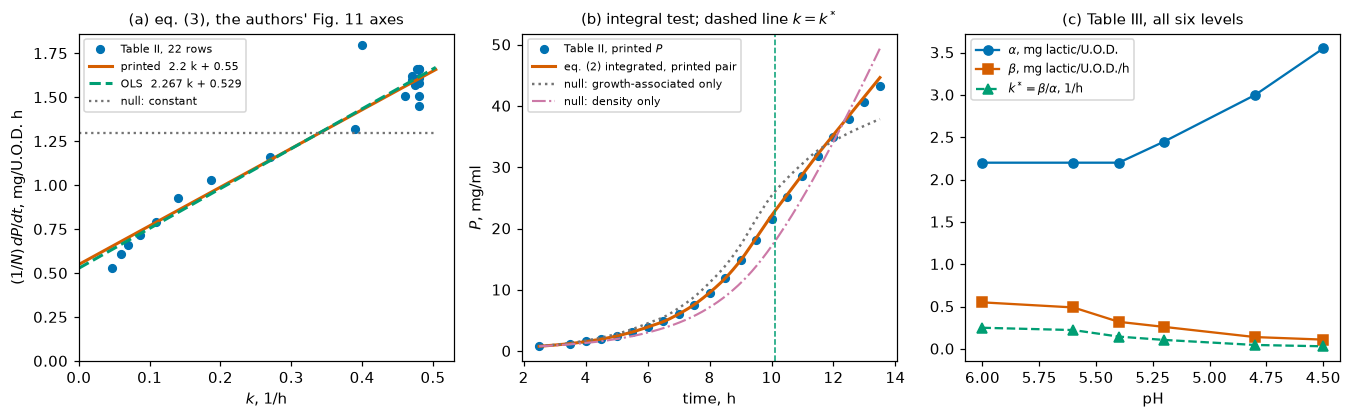

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(12.4, 3.9))
_f3 = T2.dropna(subset=["k_per_h", "invN_dPdt_mg_per_UOD_h"])
K_OBS, Y_OBS = _f3.k_per_h.to_numpy(), _f3.invN_dPdt_mg_per_UOD_h.to_numpy()
kg = np.linspace(0.0, K_OBS.max() * 1.05, 200)
ax[0].plot(K_OBS, Y_OBS, "o", ms=5, color=C_BLUE, label=f"Table II, {len(K_OBS)} rows")
ax[0].plot(kg, ALPHA_PRINTED * kg + BETA_PRINTED, "-", color=C_ORANGE, lw=2,
           label=f"printed  {ALPHA_PRINTED} k + {BETA_PRINTED}")
ax[0].plot(kg, R["alpha_refit_eq3"] * kg + R["beta_refit_eq3"], "--", color=C_GREEN, lw=2,
           label=f"OLS  {R['alpha_refit_eq3']:.3f} k + {R['beta_refit_eq3']:.3f}")
ax[0].plot(kg, np.full_like(kg, Y_OBS.mean()), ":", color=C_GREY, lw=1.5, label="null: constant")
ax[0].set_xlabel("$k$, 1/h")
ax[0].set_ylabel("$(1/N)\\,dP/dt$, mg/U.O.D. h")
ax[0].set_title("(a) eq. (3), the authors' Fig. 11 axes", fontsize=9.5)
ax[0].legend(fontsize=7.4, loc="upper left")
ax[0].set_xlim(0, None)
ax[0].set_ylim(0, None)

tg = np.linspace(TP[0], T_HI, 400)
_ai = float(ols((NT2(TP) - NT2(TP[0]))[:, None], P_OBS - P_OBS[0])[0])
_bi = float(ols((NT2_INT(TP) - NT2_INT(TP[0]))[:, None], P_OBS - P_OBS[0])[0])
ax[1].plot(TP, P_OBS, "o", ms=5, color=C_BLUE, label="Table II, printed $P$")
ax[1].plot(tg, P_OBS[0] + ALPHA_PRINTED * (NT2(tg) - NT2(TP[0]))
           + BETA_PRINTED * (NT2_INT(tg) - NT2_INT(TP[0])), "-", color=C_ORANGE, lw=2,
           label="eq. (2) integrated, printed pair")
ax[1].plot(tg, P_OBS[0] + _ai * (NT2(tg) - NT2(TP[0])), ":", color=C_GREY, lw=1.6,
           label="null: growth-associated only")
ax[1].plot(tg, P_OBS[0] + _bi * (NT2_INT(tg) - NT2_INT(TP[0])), "-.", color=C_PURPLE, lw=1.4,
           label="null: density only")
ax[1].axvline(R["crossover_time_h"], color=C_GREEN, lw=1, ls="--")
ax[1].set_xlabel("time, h")
ax[1].set_ylabel("$P$, mg/ml")
ax[1].set_title("(b) integral test; dashed line $k = k^*$", fontsize=9.5)
ax[1].legend(fontsize=7.4, loc="upper left")

ax[2].plot(T3S.pH, T3S.alpha_mg_lactic_per_UOD, "o-", color=C_BLUE, label=r"$\alpha$, mg lactic/U.O.D.")
ax[2].plot(T3S.pH, T3S.beta_mg_lactic_per_UOD_h, "s-", color=C_ORANGE,
           label=r"$\beta$, mg lactic/U.O.D./h")
ax[2].plot(T3S.pH, T3S.k_star_per_h, "^--", color=C_GREEN, label=r"$k^*=\beta/\alpha$, 1/h")
ax[2].set_xlabel("pH")
ax[2].set_title("(c) Table III, all six levels", fontsize=9.5)
ax[2].legend(fontsize=7.6)
ax[2].invert_xaxis()
fig.tight_layout()
plt.show()

## Validation

**The strongest validation of a product-formation law would be a fermentation the
constants were not fitted to. This paper prints exactly one fermentation's raw
data, and it is the one the pH 6·0 constants were fitted to**, so that validation
is not available and is not manufactured. What the printed numbers support, in
descending order of what it proves:

1. **Internal identities of Table II** (transcription checks, by the paper's own
   definitions on book p. 400), with their reach measured.
2. **A second, independent column path** for the crossover time, on the $k$
   column and on the separate $\mathrm{d}N/\mathrm{d}t$ and $N$ columns.
3. **A third fitting route that touches no differentiated column**, the integral
   form.
4. **Two solver discretisations against the closed form**, both refined, with
   observed orders and round-off companions.
5. **Two null baselines**, each the paper's own rejected alternative.
6. **Not: agreement with any plotted curve.** Figs. 4-11 are not digitised, so the
   page does not establish empirical adequacy against anything that lives only in
   a figure, including all five other pH levels.

### What this page cannot conclude

- **That the Luedeking-Piret relation is correct.** One run, and the constants
  were fitted on it; the refit tests the arithmetic of the authors' fit.
- **That the form holds across pH.** That needs the five other runs' raw data.
- **Anything about $\alpha(\mathrm{pH})$ or $\beta(\mathrm{pH})$ as functions.**
- **That the plug-flow extension describes a real fermenter.** No experiment in
  this paper is continuous.

### Claims and the defect-injection table

Every number the page states is a claim below. The break rows inject one defect
each through an argument of the study that computes the claims: a mis-transcribed
cell of one of the three tables (each a single-digit or mid-dot substitution of
the kind this scan makes), a changed method (fit window, fit variable,
interpolant, quadrature rule, outlet condition, order estimate, solver
tolerance) or a changed resolution. Each row recomputes its study and records the
claims it targets; the table lists, per row, the claims whose own check it fails.

In [14]:
# ---- claims: the table-derived results (fits to printed data, above round-off)
VALUE_CLAIMS = [
    "alpha_refit_eq3", "beta_refit_eq3", "eq3_refit_rms", "eq3_R2", "alpha_se_eq3",
    "beta_se_eq3", "alpha_beta_corr_eq3", "alpha_refit_eq3_vs_printed",
    "beta_refit_eq3_vs_printed", "printed_alpha_in_se", "printed_beta_in_se",
    "beta_given_printed_alpha", "alpha_given_printed_beta", "eq3_printed_pair_rms",
    "eq3_printed_pair_rms_penalty", "alpha_refit_eq2", "beta_refit_eq2", "eq2_refit_rms",
    "eq2_null_growth_only_rms", "eq2_null_density_only_rms", "eq2_null_growth_only_ratio",
    "eq2_null_density_only_ratio", "eq2_logphase_refit_rms",
    "eq2_logphase_null_growth_only_ratio", "eq2_logphase_null_density_only_ratio",
    "eq2_outside_log_refit_rms", "eq2_outside_log_null_growth_only_ratio",
    "eq2_outside_log_null_density_only_ratio", "alpha_refit_integral", "beta_refit_integral",
    "integral_refit_rms", "integral_null_growth_only_ratio", "integral_null_density_only_ratio",
    "alpha_route_spread", "beta_route_spread", "P_curve_rms_rel", "P_curve_max_rel",
    "P_final_vs_printed", "k_star_printed", "k_star_refit", "crossover_time_h",
    "crossover_time_dNdt_route_h", "crossover_interp_band_rel", "growth_assoc_share",
    "integrated_closure_rel", "k_identity_max_rel", "invN_identity_max_rel",
    "table1_vs_table2_N_max_rel", "table1_vs_table2_N_rms_rel", "beta_range_ph6_over_ph45",
    "alpha_range_ph45_over_ph6", "kstar_range_ph6_over_ph45", "kstar_ph45_per_h",
    "kstar_ph56_per_h", "beta_monotone_margin", "beta_sum_all_ph"]
for _name in VALUE_CLAIMS:
    claims.value(_name, R[_name])
claims.exact("n_rows_eq3", R["n_rows_eq3"])
claims.exact("ph_column_matches_text", R["ph_column_matches_text"])
claims.exact("alpha_nondecreasing", R["alpha_nondecreasing"])
claims.exact("kstar_decreasing", R["kstar_decreasing"])
claims.count("printed_pair_inside_one_se", [R["printed_alpha_in_se"], R["printed_beta_in_se"]],
             1.0, above=False, min_margin=0.3,
             note="the printed pH 6.0 alpha and beta each within one standard error of the refit")
claims.bound("crossover_two_routes_rel", R["crossover_two_routes_rel"], min=0.0, max=1e-3,
             basis="chosen", note="the two routes read different printed cells through their own"
             " interpolants; a gap beyond 1e-3 (0.6 min in 10 h) is a mis-transcribed cell")
claims.exact("j41_search_hits", J41_TOTAL_HITS)
claims.value("digit_substitution_detection", DIGIT_FRAC)

# ---- the closed form and the two pymrm models
claims.value("closed_form_N_final", N_REF)
claims.value("closed_form_P_final", P_REF)
claims.bound("batch_marcher_order", MARCH_ST["worst"], min=0.9, max=1.1, basis="theory",
             note="backward Euler is first order; worst order of the ladder 200 to 1600 steps")
claims.bound("batch_marcher_roundoff_margin", MARCH_ST["margin"], min=1e3, basis="theory",
             note="finest successive difference over n max(tol, eps |P|)")
claims.value("batch_marcher_finest_rel", MARCH_FINEST)
claims.bound("pfr_grid_order", PFR_ST["worst"], min=0.9, max=1.1, basis="theory",
             note="donor-cell upwind is first order; worst order of the ladder 200 to 3200 cells")
claims.bound("pfr_roundoff_margin", PFR_ST["margin"], min=1e3, basis="theory",
             note="finest successive difference over tol + n eps |P|")
claims.value("pfr_outlet_P_ncell3200", PFR_P_FINEST)
claims.value("pfr_richardson_vs_closed_form", PFR_P_RICH_REL)
claims.bound("pfr_boundary_over_last_cell", PFR_RATIO, min=1 - 1e-12, max=1 + 1e-12,
             basis="identity", note="under {'outflow': True} the outlet face carries the last"
             " cell's value, so the two reads coincide")
print(f"{len(claims.metrics)} claims registered")

74 claims registered


In [15]:
# ---- the break rows: each injects one defect through an argument of its study
REFIT = [n for n in claims.metrics if n in R] + ["printed_pair_inside_one_se"]


def corrupt(df, mask_col, mask_val, col, new):
    """A copy of a table with one cell replaced."""
    d = df.copy()
    d.loc[d[mask_col] == mask_val, col] = new
    return d


def refit(**kw):
    """refit_all on the given tables (the printed ones by default)."""
    t = {"t1": T1, "t2": T2, "t3": T3, "ph_text": PH_TEXT_P400}
    t.update(kw)
    out = refit_all(**t)
    out["printed_pair_inside_one_se"] = int(out["printed_alpha_in_se"] < 1.0) + int(
        out["printed_beta_in_se"] < 1.0)
    return out


def closed_and_pfr(t_bad, k_bad, ncell=PFR_N[-1]):
    """One mis-transcribed k cell, driving the plug-flow solve and its reference together."""
    kv = np.where(_kk.time_h.to_numpy() == t_bad, k_bad, _kk.k_per_h.to_numpy())
    cf = ClosedForm(_kk.time_h, kv, N_LO)
    f = PlugFlowFermenter(ncell, ALPHA_PRINTED, BETA_PRINTED, cf).solve()
    return {"closed_form_N_final": float(cf.N(T_HI)),
            "closed_form_P_final": cf.P(T_HI, ALPHA_PRINTED, BETA_PRINTED),
            "pfr_outlet_P_ncell3200": float(f.outlet()[1])}


def pfr_ladder(ladder, **kw):
    """Outlet P on a plug-flow ladder, with the claims built from it."""
    out = {n: float(PlugFlowFermenter(n, ALPHA_PRINTED, BETA_PRINTED, CF, **kw).solve().outlet()[1])
           for n in ladder}
    return out


def march_ladder(tol=1e-13):
    """The batch ladder at a given newton tolerance."""
    return {n: float(batch_march(n, ALPHA_PRINTED, BETA_PRINTED, CF, tol=tol)[1]) for n in MARCH_NT}


ROWS = [
    ("Table II: N at t = 9.50 h read 5.85 instead of 5.35",
     lambda: refit(t2=corrupt(T2, "time_h", 9.50, "N_UOD_per_ml", 5.85)), REFIT),
    ("Table II: dP/dt at t = 8.00 h read 4.87 instead of 4.37",
     lambda: refit(t2=corrupt(T2, "time_h", 8.00, "dPdt_mg_per_ml_h", 4.87)), REFIT),
    ("Table II: N at t = 8.50 h read 3.96 instead of 3.46, inside the plateau",
     lambda: refit(t2=corrupt(T2, "time_h", 8.50, "N_UOD_per_ml", 3.96)), REFIT),
    ("Table II: k at t = 10.00 h read 0.276 instead of 0.270",
     lambda: refit(t2=corrupt(T2, "time_h", 10.00, "k_per_h", 0.276)), REFIT),
    ("Table II: P at t = 13.50 h read 48.3 instead of 43.3",
     lambda: refit(t2=corrupt(T2, "time_h", 13.50, "P_mg_per_ml", 48.3)), REFIT),
    ("Table II: the one-significant-figure t = 2.50 h row dropped",
     lambda: refit(t2=T2[T2.time_h != 2.50], drop_first_P_row=True), REFIT),
    ("Table I: N at t = 9.30 h read 4.04 instead of 4.94",
     lambda: refit(t1=corrupt(T1, "time_h", 9.30, "N_UOD_per_ml", 4.04)), REFIT),
    ("Table III: the pH 5.6 stray mark read as a minus sign, beta = -0.49",
     lambda: refit(t3=corrupt(T3, "pH", 5.6, "beta_mg_lactic_per_UOD_h", -0.49)), REFIT),
    ("Table III: alpha at pH 6.0 read 2.7 instead of 2.2",
     lambda: refit(t3=corrupt(T3, "pH", 6.0, "alpha_mg_lactic_per_UOD", 2.7)), REFIT),
    ("Table III: beta at pH 6.0 read 0.35 instead of 0.55",
     lambda: refit(t3=corrupt(T3, "pH", 6.0, "beta_mg_lactic_per_UOD_h", 0.35)), REFIT),
    ("Table III: mid-dot relocated in alpha at pH 4.5, 3.55 read as 35.5",
     lambda: refit(t3=corrupt(T3, "pH", 4.5, "alpha_mg_lactic_per_UOD", 35.5)), REFIT),
    ("Table III: mid-dot dropped in beta at pH 4.5, 0.11 read as 1.1",
     lambda: refit(t3=corrupt(T3, "pH", 4.5, "beta_mg_lactic_per_UOD_h", 1.1)), REFIT),
    ("Table III: pH 5.4 read as 3.4, the text layer's own misreading",
     lambda: refit(t3=corrupt(T3, "pH", 5.4, "pH", 3.4)), REFIT),
    ("eqs. (2) and (3) fitted on the logarithmic plateau only (k >= 0.45)",
     lambda: refit(k_min=K_LOG), REFIT),
    ("eq. (3) fitted on the unrounded quotient dP/dt / N, not the printed column",
     lambda: refit(use_quotients=True), REFIT),
    ("linear interpolation of k(t) and N(t) instead of monotone cubic",
     lambda: refit(kinterp="linear"), REFIT),
    ("left-rectangle instead of trapezoid for the integrated split",
     lambda: refit(quad_rule="rect"), REFIT),
    ("J4.1 search widened by the term 'monod'",
     lambda: {"j41_search_hits": sum(j41_hits(J41_TERMS + ("monod",)).values())},
     ["j41_search_hits"]),
    ("digit detection scored at a 10x tighter tolerance",
     lambda: {"digit_substitution_detection": digit_detection(_k, K_IDENT_MAX / 10)[0] / DIGIT_TOTAL},
     ["digit_substitution_detection"]),
    ("Table II: k at t = 7.00 h read 0.98 instead of 0.48, in the solve and the reference",
     lambda: closed_and_pfr(7.00, 0.98),
     ["closed_form_N_final", "closed_form_P_final", "pfr_outlet_P_ncell3200"]),
    ("Table II: k at t = 13.50 h (the outlet cell) read 0.947 instead of 0.047",
     lambda: closed_and_pfr(13.50, 0.947),
     ["closed_form_N_final", "closed_form_P_final", "pfr_outlet_P_ncell3200"]),
    ("batch marcher at nt = 200 instead of 1600",
     lambda: {"batch_marcher_finest_rel": float(abs(MARCH[200][1] / P_REF - 1))},
     ["batch_marcher_finest_rel"]),
    ("plug flow at ncell = 200 instead of 3200 (Richardson from 100 and 200)",
     lambda: (lambda v: {"pfr_outlet_P_ncell3200": v[200],
                         "pfr_richardson_vs_closed_form": abs((2 * v[200] - v[100]) / P_REF - 1)})(
         pfr_ladder((100, 200))),
     ["pfr_outlet_P_ncell3200", "pfr_richardson_vs_closed_form"]),
    ("orders taken against the finest level instead of from successive differences",
     lambda: {"batch_marcher_order": order_study({n: MARCH[n][1] for n in MARCH_NT}, MARCH_NT,
                                                 1e-13, self_ref=True)["worst"],
              "pfr_grid_order": order_study(PFR_OUT, PFR_N, 1e-12, floor="solve",
                                            self_ref=True)["worst"]},
     ["batch_marcher_order", "pfr_grid_order"]),
    ("batch newton tolerance loosened to 1e-2",
     lambda: {"batch_marcher_roundoff_margin": order_study(march_ladder(1e-2), MARCH_NT,
                                                           1e-2)["margin"]},
     ["batch_marcher_roundoff_margin"]),
    ("plug-flow newton tolerance loosened to 1e-2",
     lambda: {"pfr_roundoff_margin": order_study(pfr_ladder(PFR_N, tol=1e-2), PFR_N, 1e-2,
                                                 floor="solve")["margin"]},
     ["pfr_roundoff_margin"]),
    ("zero-gradient outlet {a: 1, b: 0, d: 0} instead of outflow",
     lambda: {"pfr_boundary_over_last_cell": boundary_over_last_cell(_zg)},
     ["pfr_boundary_over_last_cell"]),
]

claims.define_rows([r[0] for r in ROWS])
BREAK = []
for _row, _study, _targets in ROWS:
    try:
        _out = _study()
    except Exception as exc:                 # noqa: BLE001 - a failed study is a result
        print(f"  {_row}: raised {type(exc).__name__}: {str(exc)[:70]}; records nan")
        _out = {}
    _caught = []
    for _name in _targets:
        if claims.breaks(_row, _name, _out.get(_name, np.nan)):
            _caught.append(_name)
    BREAK.append((_row, len(_targets), _caught))

for _row, _n, _caught in BREAK:
    print(f"{_row}\n    fails {len(_caught)} of {_n} targeted claims: {', '.join(_caught) or 'none'}")
_idle = [r for r, _, c in BREAK if not c]
print(f"\n{len(ROWS)} rows defined, {len(BREAK)} in the table; rows that fail no claim: {_idle or 'none'}")
_missing = [k for k in claims.metrics if not any(k in c for _, _, c in BREAK)]
print(f"claims no row fails: {_missing or 'none'}")

Table II: N at t = 9.50 h read 5.85 instead of 5.35
    fails 18 of 62 targeted claims: eq2_refit_rms, eq2_null_growth_only_ratio, eq2_null_density_only_ratio, eq2_outside_log_refit_rms, eq2_outside_log_null_growth_only_ratio, eq2_outside_log_null_density_only_ratio, integral_refit_rms, integral_null_growth_only_ratio, integral_null_density_only_ratio, alpha_route_spread, P_curve_rms_rel, P_curve_max_rel, P_final_vs_printed, integrated_closure_rel, k_identity_max_rel, invN_identity_max_rel, table1_vs_table2_N_max_rel, table1_vs_table2_N_rms_rel
Table II: dP/dt at t = 8.00 h read 4.87 instead of 4.37
    fails 5 of 62 targeted claims: eq2_logphase_refit_rms, alpha_route_spread, beta_route_spread, integrated_closure_rel, invN_identity_max_rel
Table II: N at t = 8.50 h read 3.96 instead of 3.46, inside the plateau
    fails 16 of 62 targeted claims: eq2_logphase_refit_rms, eq2_logphase_null_growth_only_ratio, eq2_logphase_null_density_only_ratio, integral_refit_rms, integral_null_growth_o

## What pymrm adds

**Not much to the fit, and the page says so.** Refitting a two-parameter linear
model to Table II's rows is `numpy.linalg.lstsq`; pymrm is not involved in the
headline numbers. What it adds is downstream of the fit:

1. **The relation as a source term.** Eq. (2) written once as `source(c)` drops
   unchanged into a batch marcher (`newton` + `NumJac((1, 2))`) and a plug-flow
   fermenter (`construct_convflux_upwind` + `construct_div`, `nu=0`,
   `{"outflow": True}` outlet read with `compute_boundary_values`), the form the
   Summary's *"rational design of continuous fermentation processes"* needs and
   the paper never writes. Both residuals are linear in (N, P);
   every solve checks `success`.
2. **A closed form to check against.** With $k(t)$ prescribed from the printed $k$
   column, eq. (2) integrates exactly, and both discretisations come back first
   order by `pymrm.checks.observed_orders`, each with its round-off margin.
3. **Crossings as checked roots.** `pymrm.checks.find_roots` scans the whole
   printed window and the page raises unless each crossing is the only one.

No new physics, no extension to unmeasured conditions, and nothing about the
five pH levels without raw data. The plug-flow model illustrates composability;
nothing in this paper tests it.

## Reuse

- **Fit $\alpha$ and $\beta$ in the variables you will report them in.** Eqs. (3)
  and (2) are the same model and two different least-squares problems; the
  spread between routes is printed in Results section 1.
- **Report $k^* = \beta/\alpha$.** It has a physical meaning, and the paper's own
  qualitative account of the fermentation is a statement about it.
- **Check a printed rate column against the columns it was divided by.** The
  share of single-digit substitutions that test catches is printed above.
- **Look for arithmetic before pixels.** Where a table has no internal identity,
  the arithmetic is often one step out: a column reprinted in running text, the
  same quantity on a zero-based axis, a monotone trend. A pixel argument should
  corroborate rather than carry.
- **Test both halves of the sentence you are quoting.** The paper says the
  one-term forms hold inside the logarithmic phase and fail outside it; the
  all-rows ratios alone hide that the constants are nearly unidentifiable exactly
  where the one-term forms work.
- **Fitted parameters at *n* conditions and raw data at one means one condition
  can be checked.** Check it properly and scope the rest out.
- **To reuse the models**, replace the prescribed $k(t)$ by a growth law (J4.1,
  J4.2) coupled through $N$; the source function and both reactor models are
  unchanged. Related: J4.1, J4.2, J4.6, J4.8, C1.1, J3.5.

In [16]:
# Prose literals: every number the README, meta.yaml and this notebook print, checked
# against its claim at the precision written.
SAYS = {
    "alpha_refit_eq3": ["2.2666"], "beta_refit_eq3": ["0.5287"],
    "alpha_refit_eq3_vs_printed": ["3.03 %"], "beta_refit_eq3_vs_printed": ["-3.88 %"],
    "printed_alpha_in_se": ["0.51"], "printed_beta_in_se": ["0.43"],
    "alpha_beta_corr_eq3": ["-0.89"], "beta_given_printed_alpha": ["0.5513"],
    "eq3_printed_pair_rms_penalty": ["0.65 %"], "n_rows_eq3": ["22"],
    "eq2_null_growth_only_ratio": ["5.55"], "eq2_null_density_only_ratio": ["4.92"],
    "eq2_logphase_null_growth_only_ratio": ["1.036"],
    "eq2_logphase_null_density_only_ratio": ["1.033"],
    "eq2_outside_log_null_growth_only_ratio": ["5.01"],
    "eq2_outside_log_null_density_only_ratio": ["3.71"],
    "integral_null_growth_only_ratio": ["14.2"], "integral_null_density_only_ratio": ["17.8"],
    "alpha_refit_integral": ["2.2727"], "beta_refit_integral": ["0.5101"],
    "alpha_route_spread": ["1.03 %"], "beta_route_spread": ["3.64 %"],
    "P_curve_rms_rel": ["1.70 %"], "P_final_vs_printed": ["3.12 %"],
    "k_identity_max_rel": ["2.74 %"], "digit_substitution_detection": ["87.4 %"],
    "crossover_time_h": ["10.1"], "crossover_interp_band_rel": ["0.16 %"],
    "growth_assoc_share": ["46.7 %"], "beta_range_ph6_over_ph45": ["5.0"],
    "alpha_range_ph45_over_ph6": ["1.61"], "kstar_range_ph6_over_ph45": ["8.07"],
    "batch_marcher_order": ["between 0.9 and 1.1"], "pfr_grid_order": ["between 0.9 and 1.1"],
    "pfr_richardson_vs_closed_form": ["2.2e-5"],
}
for _k, _lits in SAYS.items():
    for _lit in _lits:
        claims.says(_lit, _k)
print(f"prose literals: {sum(len(v) for v in SAYS.values())} checked against their claims with claims.says")
claims.report();   # the semicolon keeps the notebook from echoing the payload

prose literals: 35 checked against their claims with claims.says
Claims for J4.4:
  alpha_refit_eq3                         = 2.2666           value  rtol 0.05
  beta_refit_eq3                          = 0.52868          value  rtol 0.05
  eq3_refit_rms                           = 0.10079          value  rtol 0.05
  eq3_R2                                  = 0.93744          value  rtol 0.05
  alpha_se_eq3                            = 0.13093          value  rtol 0.05
  beta_se_eq3                             = 0.049837         value  rtol 0.05
  alpha_beta_corr_eq3                     = -0.8919          value  rtol 0.05
  alpha_refit_eq3_vs_printed              = 0.030256         value  rtol 0.05
  beta_refit_eq3_vs_printed               = -0.038757        value  rtol 0.05
  printed_alpha_in_se                     = 0.50839          value  rtol 0.05
  printed_beta_in_se                      = 0.42771          value  rtol 0.05
  beta_given_printed_alpha                = 0.55128         